In [1]:
import os
import pathlib
import kagglehub

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score)

In [2]:
SEED=42

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# downlaoding the kaggle data set

In [5]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [6]:
os.listdir(path + "/chest_xray/train/")

['PNEUMONIA', 'NORMAL']

In [7]:
data_dir  = path + "/chest_xray"

print("Train NORMAL   :", len(os.listdir(data_dir + "/train/NORMAL")))
print("Train PNEUMONIA:", len(os.listdir(data_dir + "/train/PNEUMONIA")))
print("Val NORMAL     :", len(os.listdir(data_dir + "/val/NORMAL")))
print("Val PNEUMONIA  :", len(os.listdir(data_dir + "/val/PNEUMONIA")))
print("Test NORMAL    :", len(os.listdir(data_dir + "/test/NORMAL")))
print("Test PNEUMONIA :", len(os.listdir(data_dir + "/test/PNEUMONIA")))

Train NORMAL   : 1341
Train PNEUMONIA: 3875
Val NORMAL     : 8
Val PNEUMONIA  : 8
Test NORMAL    : 234
Test PNEUMONIA : 390


In [8]:
#imbalance can be seen in the training data set

In [9]:
#load the data set

In [10]:
data_root = pathlib.Path(data_dir)
type(data_root)

pathlib._local.PosixPath

In [11]:
data_root = pathlib.Path(data_dir)
train_dir = data_root / "train"
test_dir = data_root / "test"

IMG_SIZE = (180, 180)
BATCH_SIZE = 64

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
)

print("-"*50)

val_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

print("-"*50)

test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("-"*50)


Found 5216 files belonging to 2 classes.
Using 4173 files for training.
--------------------------------------------------
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
--------------------------------------------------
Found 624 files belonging to 2 classes.
--------------------------------------------------


In [13]:
class_names = train_ds.class_names
print(class_names)

['NORMAL', 'PNEUMONIA']


In [15]:
type(train_ds)

tensorflow.python.data.ops.prefetch_op._PrefetchDataset

In [16]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))>

In [17]:
images, labels = next(iter(train_ds))

In [18]:
images.shape

TensorShape([64, 180, 180, 3])

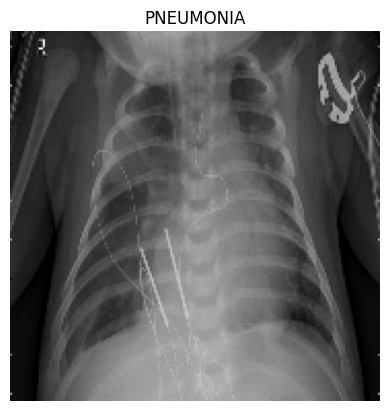

In [20]:
plt.imshow(images[0].numpy().astype("uint8"))
plt.title(class_names[int(labels[0][0])])
plt.axis("off")
plt.show()

In [21]:
#prefetch and autotune

In [22]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [23]:
# buid the NN

In [28]:
from matplotlib.cbook import flatten
model= keras.Sequential([
    keras.Input(shape=(180,180,3)),

    #normalization
    keras.layers.Rescaling(1.0/255),
    #data augmentation
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomZoom(0.05),
    keras.layers.RandomContrast(0.05),

    #convo layer 1

    keras.layers.Conv2D(32, (3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2)),

    keras.layers.Conv2D(64, (3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2)),

    #convo layer 2
    keras.layers.Conv2D(128, (3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2)),

    #flattening
    keras.layers.Flatten(),

    #fully connected layer
    keras.layers.Dense(128,activation="relu"),

    keras.layers.Dropout(0.5),

    #output layer

    keras.layers.Dense(1, activation="sigmoid")



])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_2               │ (None, 180, 180, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[keras.metrics.F1Score(average="macro",threshold=0.7)]
)

In [30]:
#training
#to counter the class imbalance we are using class weights

In [31]:
n_normal = len(os.listdir(train_dir / "NORMAL"))
n_pneumonia = len(os.listdir(train_dir / "PNEUMONIA"))

total = n_normal + n_pneumonia

class_weight = {
    0: total / (2 * n_normal),
    1: total / (2 * n_pneumonia)
}

print(class_weight)

{0: 1.9448173005219984, 1: 0.6730322580645162}


In [32]:
CallbackRegistry=[
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=3, factor=0.5, min_lr=1e-6)

]

In [36]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weight,
    callbacks=CallbackRegistry
)

Epoch 1/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 49s 565ms/step - f1_score: 0.5415 - loss: 0.5437 - val_f1_score: 0.8643 - val_loss: 0.2987 - learning_rate: 0.0010
Epoch 2/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 70s 525ms/step - f1_score: 0.8885 - loss: 0.2607 - val_f1_score: 0.8491 - val_loss: 0.3728 - learning_rate: 0.0010
Epoch 3/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 37s 470ms/step - f1_score: 0.9093 - loss: 0.2246 - val_f1_score: 0.8600 - val_loss: 0.2934 - learning_rate: 0.0010
Epoch 4/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 33s 508ms/step - f1_score: 0.9292 - loss: 0.1784 - val_f1_score: 0.9611 - val_loss: 0.1185 - learning_rate: 0.0010
Epoch 5/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 41s 512ms/step - f1_score: 0.9317 - loss: 0.1694 - val_f1_score: 0.9668 - val_loss: 0.0945 - learning_rate: 0.0010
Epoch 6/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 33s 499ms/step - f1_score: 0.9422 - loss: 0.1536 - val_f1_score: 0.9534 - val_loss: 0.1232 - learning_rate: 0.0010
Epoch 7/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 34s 504ms/step - f1_score: 0.9445 - loss: 0.

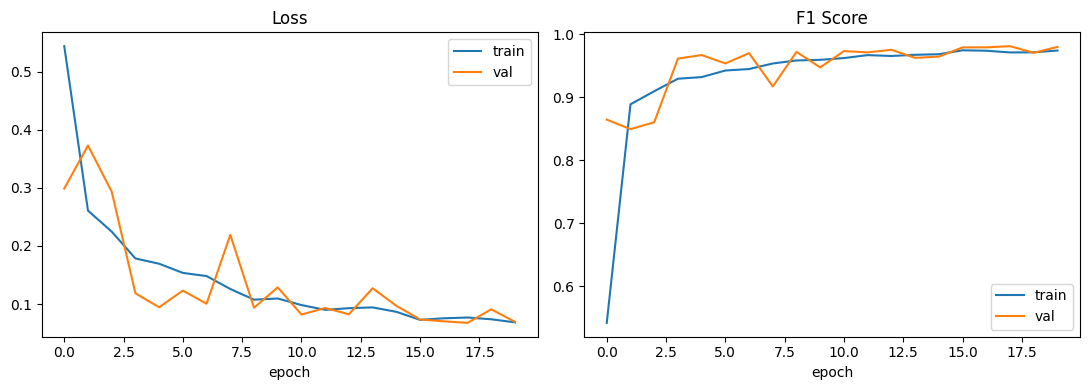

In [37]:
#learning curves
hist = history.history

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(hist["loss"], label="train")
plt.plot(hist["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist["f1_score"], label="train")
plt.plot(hist["val_f1_score"], label="val")
plt.title("F1 Score"); plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.show()

In [38]:
test_loss, test_f1_score = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test F1 Score:", test_f1_score)

10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 478ms/step - f1_score: 0.8797 - loss: 0.6572
Test Loss: 0.657157838344574
Test F1 Score: 0.8797250986099243


In [39]:
y_true = np.concatenate([labels.numpy() for images, labels in test_ds], axis=0).astype(int).ravel()
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

print("y_true:", y_true.shape, " y_prob:", y_prob.shape)

y_true: (624,)  y_prob: (624,)


In [40]:
print("ROC-AUC Score:", roc_auc_score(y_true, y_prob))

ROC-AUC Score: 0.9564486083716853


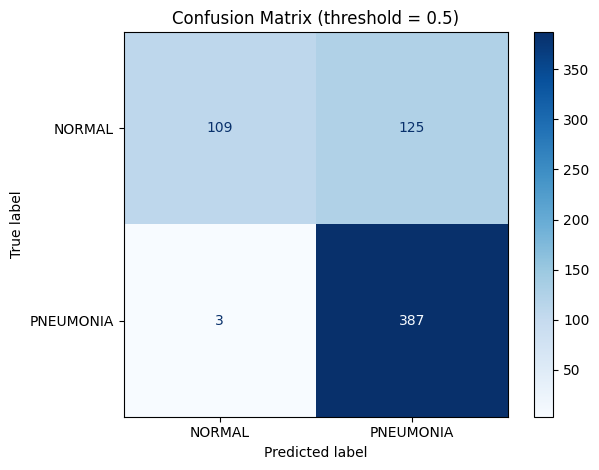

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion Matrix (threshold = 0.5)")
plt.tight_layout()
plt.show()

In [42]:
print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

      NORMAL       0.97      0.47      0.63       234
   PNEUMONIA       0.76      0.99      0.86       390

    accuracy                           0.79       624
   macro avg       0.86      0.73      0.74       624
weighted avg       0.84      0.79      0.77       624

